In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import warnings
warnings.filterwarnings("ignore")

import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import *
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.convnext import ConvNeXtTiny # Corrected this line
from tensorflow.keras.applications.convnext import preprocess_input # Corrected this line
from tensorflow.keras.optimizers import Adam
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# ============================
# 🚀 GPU (T4)
# ============================
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy('mixed_float16')

gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

# ============================
# 📁 Paths
# ============================
BASE_PATH = '/content/drive/MyDrive/iCTCF_CT_New'
train_dir = f'{BASE_PATH}/train'
val_dir   = f'{BASE_PATH}/validation'
test_dir  = f'{BASE_PATH}/test'

# ============================
# ⚙️ Parameters
# ============================
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 3

BASE_LR = 1e-4
FINE_LR = 1e-5

In [ ]:
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=15,
    zoom_range=0.15,
    brightness_range=[0.9, 1.1],
    horizontal_flip=True,
    width_shift_range=0.05,
    height_shift_range=0.05
)

val_test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

val_gen = val_test_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_gen = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

# class weights
labels = train_gen.classes
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(labels),
    y=labels
)
class_weights = dict(enumerate(class_weights))

Found 5389 images belonging to 3 classes.
Found 1797 images belonging to 3 classes.
Found 1798 images belonging to 3 classes.


In [ ]:
base_model = ConvNeXtTiny(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = BatchNormalization()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)

outputs = Dense(NUM_CLASSES, activation='softmax', dtype='float32')(x)

model = Model(inputs=base_model.input, outputs=outputs)

model.compile(
    optimizer=Adam(learning_rate=BASE_LR),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=['accuracy']
)

In [ ]:
import tensorflow as tf

DATE = "2026-04-28"
best_path = f"{BASE_PATH}/best_ConvNeXtTiny_base_{DATE}.keras"

base_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    best_path,
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=6,
    min_delta=0.001,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.3,
    patience=4,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=60,
    class_weight=class_weights,
    callbacks=[base_checkpoint, early_stop, reduce_lr]
)

# تحميل أفضل موديل محفوظ
best_base = tf.keras.models.load_model(best_path)

# حفظ نسخة نهائية منظمة
final_path = f"{BASE_PATH}/final_best_ConvNeXtTiny_base_{DATE}.keras"
best_base.save(final_path)

print("✅ Best BASE model saved:", final_path)

Epoch 1/60
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 8s/step - accuracy: 0.5610 - loss: 1.0489
Epoch 1: val_loss improved from None to 0.68049, saving model to /content/drive/MyDrive/iCTCF_CT_New/best_ConvNeXtTiny_base_2026-04-28.keras

Epoch 1: finished saving model to /content/drive/MyDrive/iCTCF_CT_New/best_ConvNeXtTiny_base_2026-04-28.keras
169/169 ━━━━━━━━━━━━━━━━━━━━ 2099s 12s/step - accuracy: 0.6881 - loss: 0.8233 - val_accuracy: 0.8219 - val_loss: 0.6805 - learning_rate: 1.0000e-04
Epoch 2/60
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 650ms/step - accuracy: 0.8511 - loss: 0.5706
Epoch 2: val_loss improved from 0.68049 to 0.55902, saving model to /content/drive/MyDrive/iCTCF_CT_New/best_ConvNeXtTiny_base_2026-04-28.keras

Epoch 2: finished saving model to /content/drive/MyDrive/iCTCF_CT_New/best_ConvNeXtTiny_base_2026-04-28.keras
169/169 ━━━━━━━━━━━━━━━━━━━━ 126s 741ms/step - accuracy: 0.8618 - loss: 0.5629 - val_accuracy: 0.8525 - val_loss: 0.5590 - learning_rate: 1.0000e-04
Epoch 3/60
169/169 ━━━━

In [ ]:
import tensorflow as tf
from tensorflow.keras.optimizers import Adam

DATE = "2026-04-28"

# =========================
# Fine-tuning strategy
# =========================
base_model.trainable = True


for layer in base_model.layers[:-int(len(base_model.layers) * 0.2)]:
    layer.trainable = False


for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False


# =========================
# Compile
# =========================
model.compile(
    optimizer=Adam(learning_rate=FINE_LR),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=['accuracy']
)


# =========================
# Checkpoint
# =========================
fine_path = f"{BASE_PATH}/best_finetuned_ConvNeXtTiny_{DATE}.keras"

fine_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    fine_path,
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)


# =========================
# Training
# =========================
history_fine = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=40,
    class_weight=class_weights,
    callbacks=[fine_checkpoint, early_stop, reduce_lr]
)


# =========================
# Save best model
# =========================
best_fine = tf.keras.models.load_model(fine_path)

final_path = f"{BASE_PATH}/final_best_finetuned_ConvNeXtTiny_{DATE}.keras"
best_fine.save(final_path)

print("✅ Best FINE-TUNED model saved:", final_path)

Epoch 1/40
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 971ms/step - accuracy: 0.9636 - loss: 0.4005
Epoch 1: val_loss improved from None to 0.42345, saving model to /content/drive/MyDrive/iCTCF_CT_New/best_finetuned_ConvNeXtTiny_2026-04-28.keras

Epoch 1: finished saving model to /content/drive/MyDrive/iCTCF_CT_New/best_finetuned_ConvNeXtTiny_2026-04-28.keras
169/169 ━━━━━━━━━━━━━━━━━━━━ 293s 1s/step - accuracy: 0.9633 - loss: 0.4017 - val_accuracy: 0.9405 - val_loss: 0.4234 - learning_rate: 1.0000e-05
Epoch 2/40
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 685ms/step - accuracy: 0.9605 - loss: 0.4018
Epoch 2: val_loss improved from 0.42345 to 0.41716, saving model to /content/drive/MyDrive/iCTCF_CT_New/best_finetuned_ConvNeXtTiny_2026-04-28.keras

Epoch 2: finished saving model to /content/drive/MyDrive/iCTCF_CT_New/best_finetuned_ConvNeXtTiny_2026-04-28.keras
169/169 ━━━━━━━━━━━━━━━━━━━━ 135s 798ms/step - accuracy: 0.9640 - loss: 0.3981 - val_accuracy: 0.9432 - val_loss: 0.4172 - learning_rate: 1.0000e-05
Ep


Evaluating Base Model...
57/57 ━━━━━━━━━━━━━━━━━━━━ 790s 13s/step - accuracy: 0.9316 - loss: 0.4366
57/57 ━━━━━━━━━━━━━━━━━━━━ 63s 530ms/step

Evaluating Fine-tuned Model...
57/57 ━━━━━━━━━━━━━━━━━━━━ 62s 500ms/step - accuracy: 0.9672 - loss: 0.3868
57/57 ━━━━━━━━━━━━━━━━━━━━ 63s 530ms/step

                 Overall Accuracy Comparison
Base Model Test Accuracy:       0.9316
Fine-tuned Model Test Accuracy: 0.9672

                 Detailed Classification Report: Base Model
              precision    recall  f1-score   support

        NiCT       0.92      0.99      0.96       579
         nCT       1.00      0.88      0.93       899
         pCT       0.81      0.98      0.89       320

    accuracy                           0.93      1798
   macro avg       0.91      0.95      0.93      1798
weighted avg       0.94      0.93      0.93      1798


                 Detailed Classification Report: Fine-tuned Model
              precision    recall  f1-score   support

        NiCT       

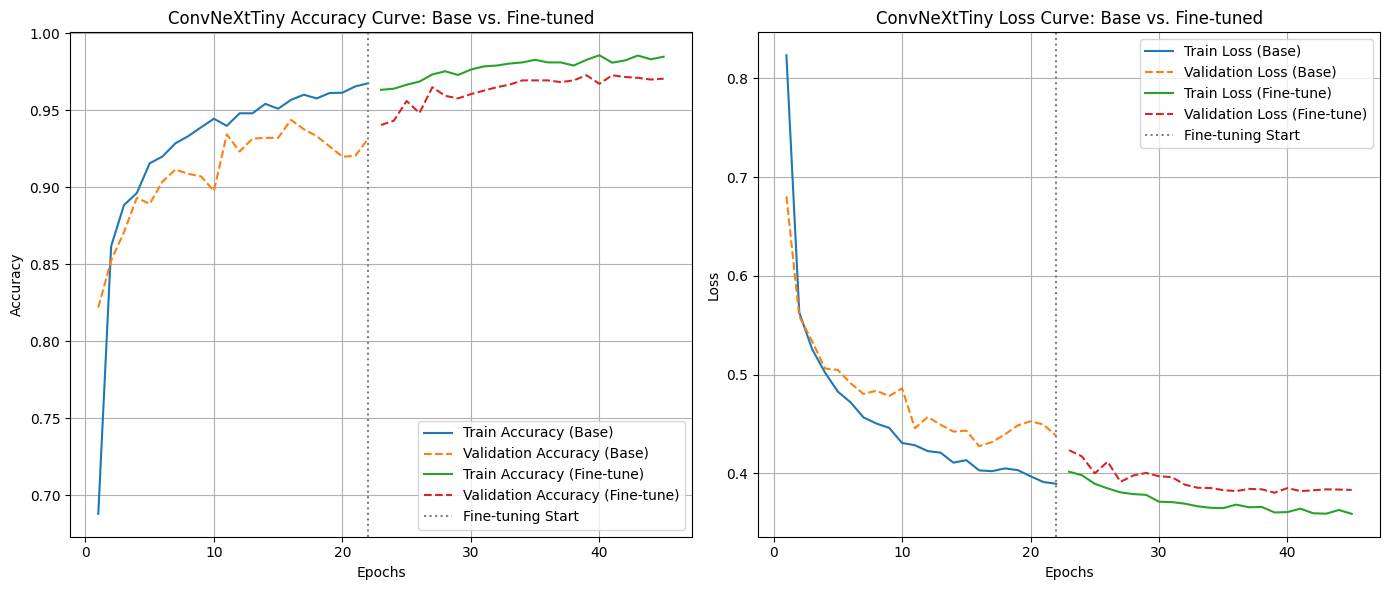

In [ ]:
from tensorflow.keras.models import load_model
from sklearn.metrics import classification_report, accuracy_score

# Load the saved models
base_model_path = '/content/drive/MyDrive/iCTCF_CT_New/final_best_ConvNeXtTiny_base_2026-04-28.keras'
finetuned_model_path = '/content/drive/MyDrive/iCTCF_CT_New/final_best_finetuned_ConvNeXtTiny_2026-04-28.keras'

# It's important to compile the model after loading if you plan to continue training or evaluating with specific metrics/loss
# For evaluation only, recompilation might not be strictly necessary if the original compilation config is saved, but it's good practice.

# Load base model
model_base = load_model(base_model_path)

# Evaluate base model
print("\nEvaluating Base Model...")
base_eval = model_base.evaluate(test_gen, verbose=1)
test_acc_base = base_eval[1]

# Get predictions for base model classification report
y_pred_base = np.argmax(model_base.predict(test_gen), axis=1)
y_true_base = test_gen.classes
report_base = classification_report(y_true_base, y_pred_base, target_names=list(test_gen.class_indices.keys()))


# Load fine-tuned model
model_finetuned = load_model(finetuned_model_path)

# Evaluate fine-tuned model
print("\nEvaluating Fine-tuned Model...")
finetuned_eval = model_finetuned.evaluate(test_gen, verbose=1)
test_acc = finetuned_eval[1]

# Get predictions for fine-tuned model classification report
y_pred_finetuned = np.argmax(model_finetuned.predict(test_gen), axis=1)
y_true_finetuned = test_gen.classes
report = classification_report(y_true_finetuned, y_pred_finetuned, target_names=list(test_gen.class_indices.keys()))



print("\n" + "="*80)
print("                 Overall Accuracy Comparison")
print("="*80)

print(f"Base Model Test Accuracy:       {test_acc_base:.4f}")
print(f"Fine-tuned Model Test Accuracy: {test_acc:.4f}")

print("\n" + "="*80)
print("                 Detailed Classification Report: Base Model")
print("="*80)
print(report_base)

print("\n" + "="*80)
print("                 Detailed Classification Report: Fine-tuned Model")
print("="*80)
print(report)

print("\n" + "="*80)
print("                 Accuracy and Loss Curves (Base Training & Fine-tuning Combined)")
print("="*80)

plt.figure(figsize=(14, 6))

# Combine histories for plotting
total_accuracy = history.history['accuracy'] + history_fine.history['accuracy']
total_val_accuracy = history.history['val_accuracy'] + history_fine.history['val_accuracy']
total_loss = history.history['loss'] + history_fine.history['loss']
total_val_loss = history.history['val_loss'] + history_fine.history['val_loss']

epochs_base = len(history.history['accuracy'])
epochs_fine = len(history_fine.history['accuracy'])
total_epochs = epochs_base + epochs_fine

plt.subplot(1, 2, 1)
plt.plot(range(1, epochs_base + 1), history.history['accuracy'], label='Train Accuracy (Base)')
plt.plot(range(1, epochs_base + 1), history.history['val_accuracy'], label='Validation Accuracy (Base)', linestyle='--')
plt.plot(range(epochs_base + 1, total_epochs + 1), history_fine.history['accuracy'], label='Train Accuracy (Fine-tune)')
plt.plot(range(epochs_base + 1, total_epochs + 1), history_fine.history['val_accuracy'], label='Validation Accuracy (Fine-tune)', linestyle='--')
plt.axvline(x=epochs_base, color='gray', linestyle=':', label='Fine-tuning Start')
plt.title('ConvNeXtTiny Accuracy Curve: Base vs. Fine-tuned') # Corrected title
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(range(1, epochs_base + 1), history.history['loss'], label='Train Loss (Base)')
plt.plot(range(1, epochs_base + 1), history.history['val_loss'], label='Validation Loss (Base)', linestyle='--')
plt.plot(range(epochs_base + 1, total_epochs + 1), history_fine.history['loss'], label='Train Loss (Fine-tune)')
plt.plot(range(epochs_base + 1, total_epochs + 1), history_fine.history['val_loss'], label='Validation Loss (Fine-tune)', linestyle='--')
plt.axvline(x=epochs_base, color='gray', linestyle=':', label='Fine-tuning Start')
plt.title('ConvNeXtTiny Loss Curve: Base vs. Fine-tuned') # Corrected title
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
print("\nBase Model Summary:")
model_base.summary()

print("\nFine-tuned Model Summary:")
model_finetuned.summary()


Base Model Summary:


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_pres… │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stem  │ (None, 56, 56,    │      4,896 │ convnext_tiny_pr… │
│ (Sequential)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │      4,800 │ convnext_tiny_st… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │        192 │ convnext_tiny_st… │
│ (LayerNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │     37,248 │ convnext_tiny_st… │
│ (Dense)             │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │          0 │ convnext_tiny_st… │
│ (Activation)        │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │     36,960 │ convnext_tiny_st… │
│ (Dense)             │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │         96 │ convnext_tiny_st… │
│ (LayerScale)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │          0 │ convnext_tiny_st… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 56, 56,    │          0 │ convnext_tiny_st… │
│                     │ 96)               │            │ convnext_tiny_st… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │      4,800 │ add[0][0]         │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │        192 │ convnext_tiny_st… │
│ (LayerNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │     37,248 │ convnext_tiny_st… │
│ (Dense)             │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │          0 │ convnext_tiny_st… │
│ (Activation)        │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │     36,960 │ convnext_tiny_st… │
│ (Dense)             │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny_stag… │ (None, 56, 56,    │         96 │ convnext_tiny_st

 Total params: 28,122,735 (107.28 MB)

 Trainable params: 100,355 (392.01 KB)

 Non-trainable params: 27,821,664 (106.13 MB)

... (4 outputs left out)

 Total params: 60,248,175 (229.83 MB)

 Trainable params: 16,163,075 (61.66 MB)

 Non-trainable params: 11,758,944 (44.86 MB)

 Optimizer params: 32,326,156 (123.31 MB)

### Confusion Matrix

A confusion matrix is a table that is often used to describe the performance of a classification model on a set of test data for which the true values are known. It allows visualization of the performance of an algorithm. Each row of the matrix represents the instances in an actual class while each column represents the instances in a predicted class, or vice versa. The name stems from the fact that it makes it easy to see if the system is confusing two classes (i.e. commonly mislabeling one as another).

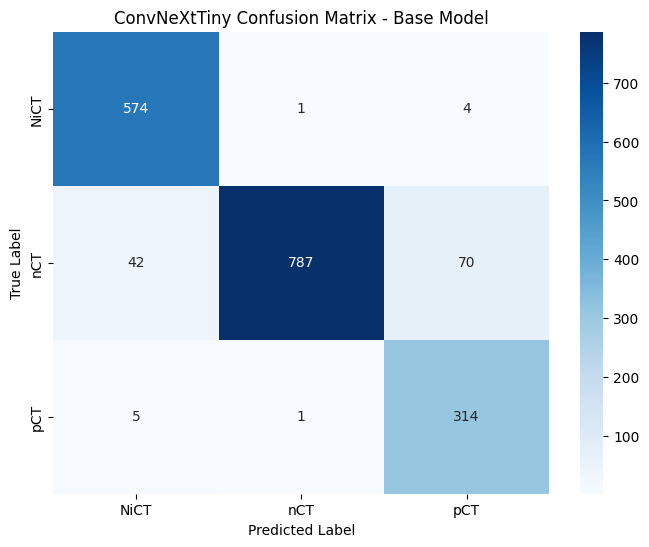

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Assuming `test_gen`, `y_true_base`, `y_pred_base`, and `class_names` are already defined
class_names = list(test_gen.class_indices.keys())

# Confusion Matrix for Base Model
cm_base = confusion_matrix(y_true_base, y_pred_base)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_base, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('ConvNeXtTiny Confusion Matrix - Base Model')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

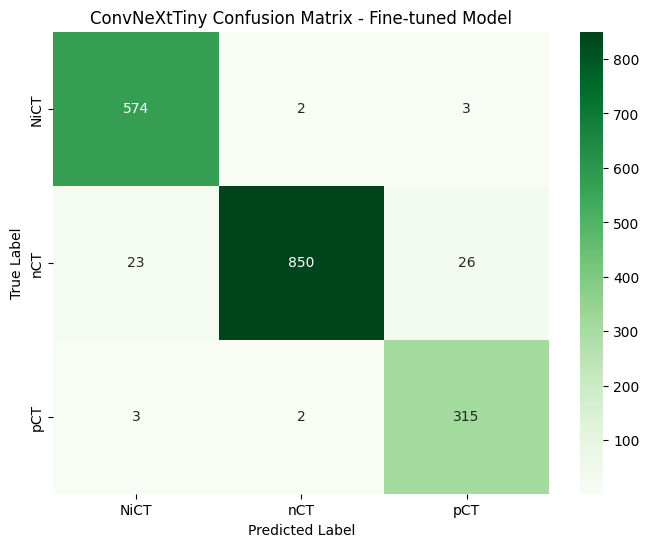

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Assuming `test_generator`, `y_true_finetuned`, `y_pred_finetuned`, and `class_names` are already defined
class_names = list(test_gen.class_indices.keys())

# Confusion Matrix for Fine-tuned Model
cm_finetuned = confusion_matrix(y_true_finetuned, y_pred_finetuned)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_finetuned, annot=True, fmt='d', cmap='Greens', xticklabels=class_names, yticklabels=class_names)
plt.title('ConvNeXtTiny Confusion Matrix - Fine-tuned Model')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

### ROC and AUC Curves

The Receiver Operating Characteristic (ROC) curve is a graphical plot that illustrates the diagnostic ability of a binary classifier system as its discrimination threshold is varied. The Area Under the Curve (AUC) is the measure of the ability of a classifier to distinguish between classes and is used as a summary of the ROC curve. The higher the AUC, the better the model is at predicting 0s as 0s and 1s as 1s.


Calculating ROC and AUC for Base Model...
57/57 ━━━━━━━━━━━━━━━━━━━━ 15s 258ms/step


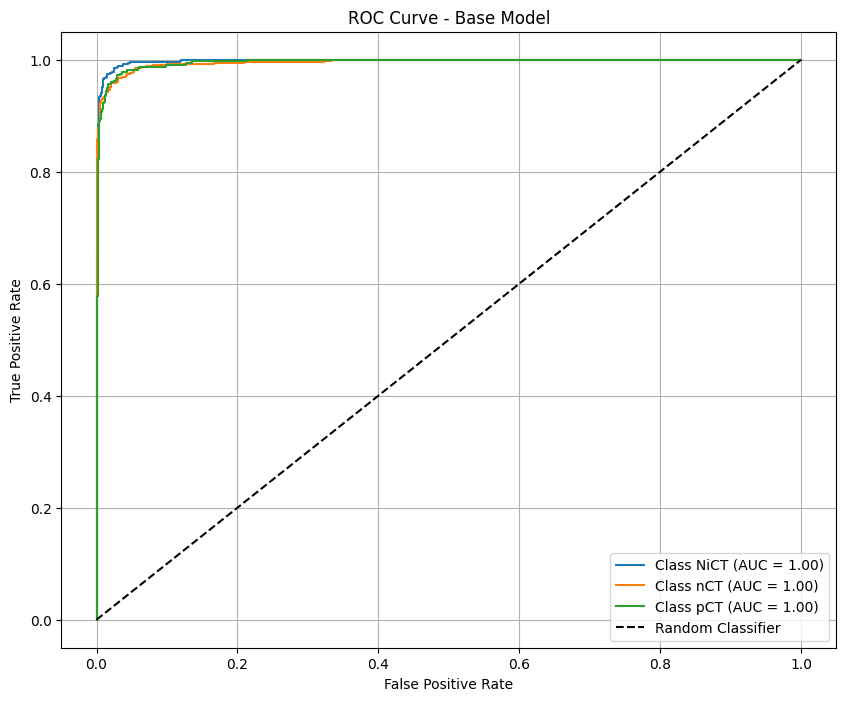

In [ ]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import LabelBinarizer

# Get true labels in one-hot encoded format
# y_true_base and y_true_finetuned are integer labels. We need them as one-hot for roc_curve.
label_binarizer = LabelBinarizer()
y_true_one_hot = label_binarizer.fit_transform(y_true_finetuned) # Assuming y_true_base and y_true_finetuned are the same
n_classes = len(class_names)

# ===============================================
# ROC and AUC for Base Model
# ===============================================
print("\nCalculating ROC and AUC for Base Model...")
y_pred_proba_base = model_base.predict(test_gen)

plt.figure(figsize=(10, 8))
for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_true_one_hot[:, i], y_pred_proba_base[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'Class {class_names[i]} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Base Model')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


Calculating ROC and AUC for Fine-tuned Model...
57/57 ━━━━━━━━━━━━━━━━━━━━ 16s 284ms/step


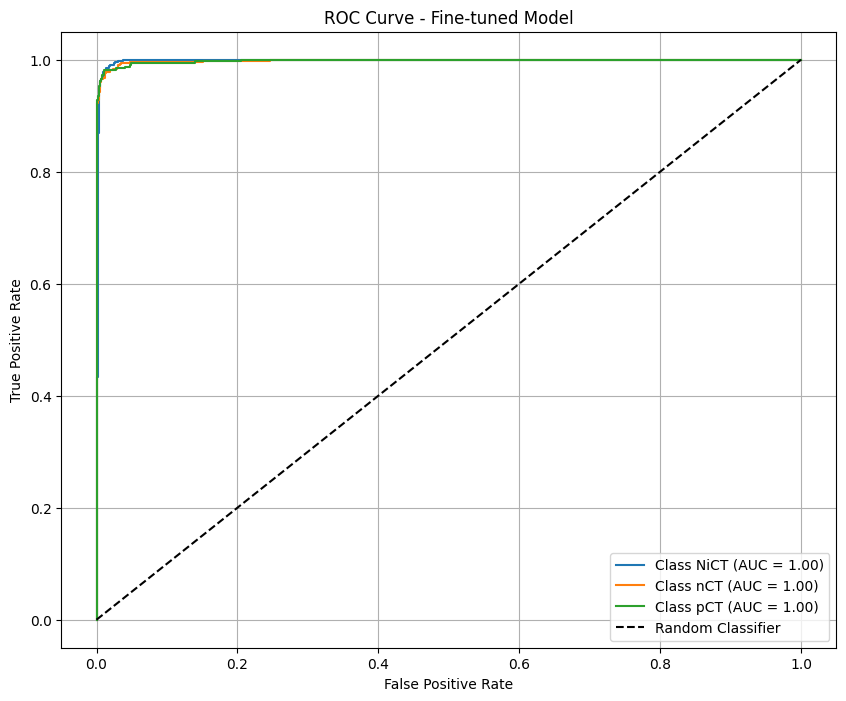

In [ ]:
# ===============================================
# ROC and AUC for Fine-tuned Model
# ===============================================
print("\nCalculating ROC and AUC for Fine-tuned Model...")
y_pred_proba_finetuned = model_finetuned.predict(test_gen)

plt.figure(figsize=(10, 8))
for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_true_one_hot[:, i], y_pred_proba_finetuned[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'Class {class_names[i]} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Fine-tuned Model')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

### Grad-CAM Visualization

This section generates Grad-CAM (Gradient-weighted Class Activation Mapping) visualizations for the fine-tuned model. Grad-CAM helps to understand which parts of an input image are most important for the model's prediction.

We will re-initialize all necessary paths, data generators, and load the fine-tuned model to ensure the code runs independently, preventing previous `NameError` issues.

In [ ]:
!pip install tf-keras-vis

Found 1798 images belonging to 3 classes.


/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 86 variables whereas the saved optimizer has 90 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Loaded fine-tuned model from: /content/drive/MyDrive/iCTCF_CT_New/final_best_finetuned_ConvNeXtTiny_2026-04-28.keras
Grad-CAM outputs will be saved to: /content/drive/MyDrive/iCTCF_CT_New/ConvNeXtTiny-28-4/gradcam_outputs
Generating Grad-CAM for 3 images from each of the 3 classes from the test set...

--- Image for NiCT (Total 1) ---
Sample Image True Class: NiCT
Sample Image Predicted Class: NiCT (Confidence: 97.20%)


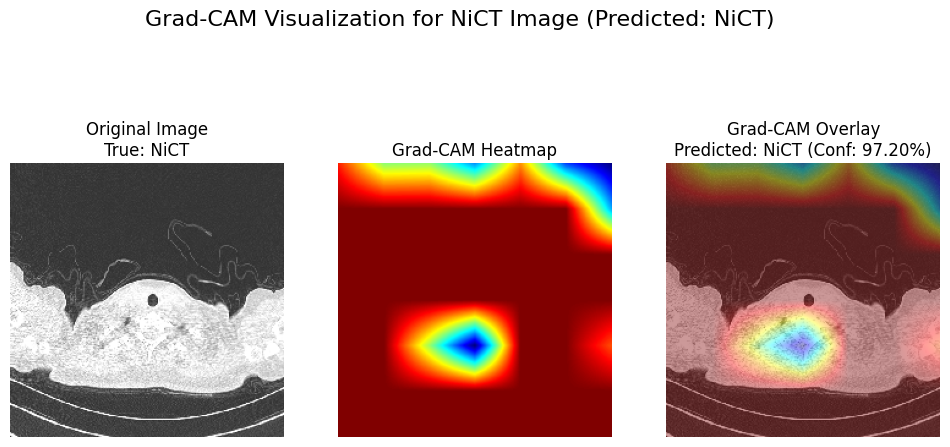


--- Image for NiCT (Total 2) ---
Sample Image True Class: NiCT
Sample Image Predicted Class: NiCT (Confidence: 97.91%)


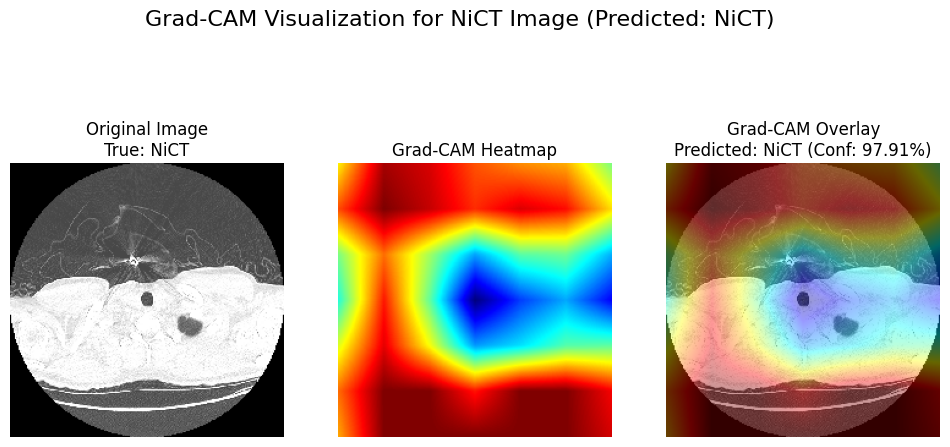


--- Image for NiCT (Total 3) ---
Sample Image True Class: NiCT
Sample Image Predicted Class: NiCT (Confidence: 93.68%)


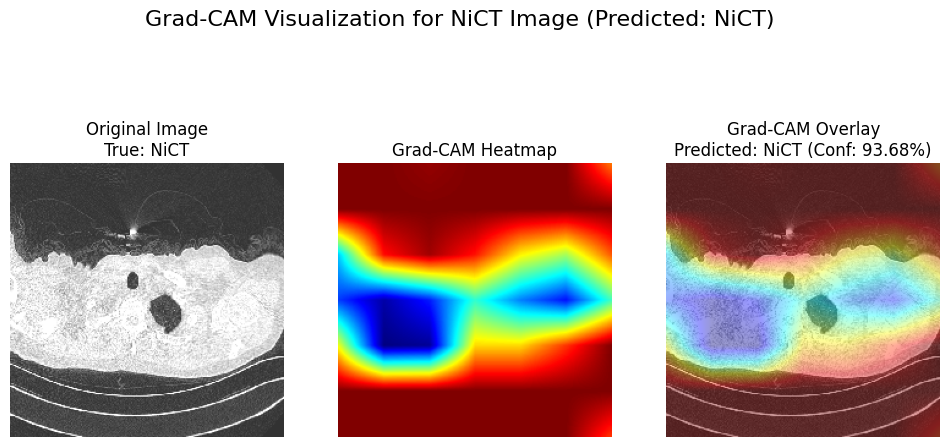


--- Image for nCT (Total 1) ---
Sample Image True Class: nCT
Sample Image Predicted Class: nCT (Confidence: 91.54%)


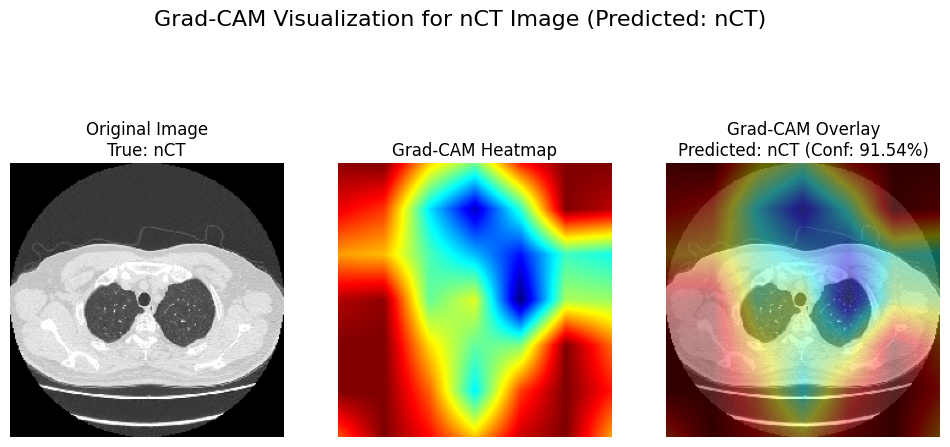


--- Image for nCT (Total 2) ---
Sample Image True Class: nCT
Sample Image Predicted Class: nCT (Confidence: 85.58%)


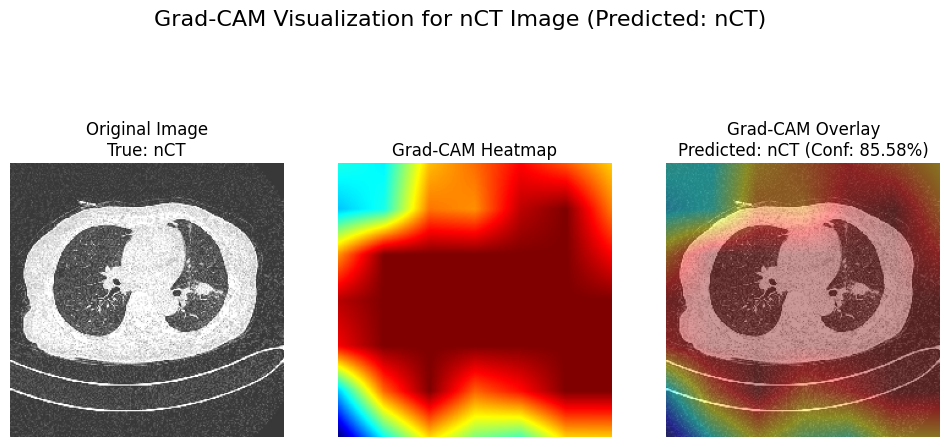


--- Image for nCT (Total 3) ---
Sample Image True Class: nCT
Sample Image Predicted Class: nCT (Confidence: 51.68%)


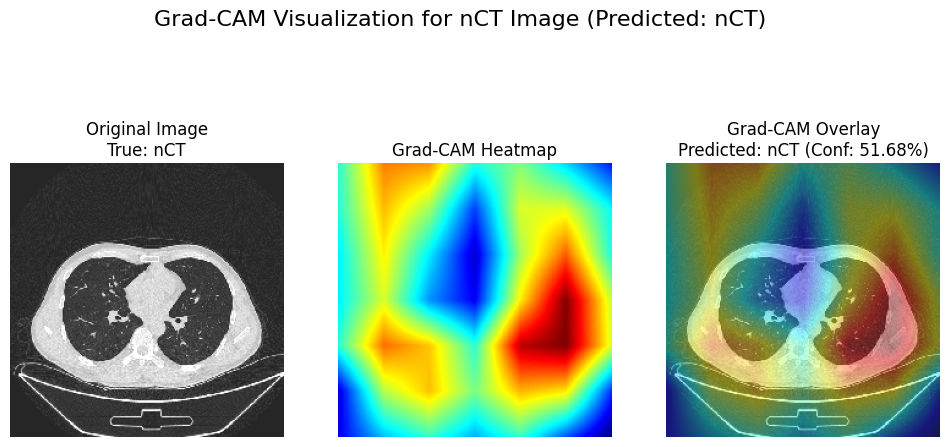


--- Image for pCT (Total 1) ---
Sample Image True Class: pCT
Sample Image Predicted Class: pCT (Confidence: 99.30%)


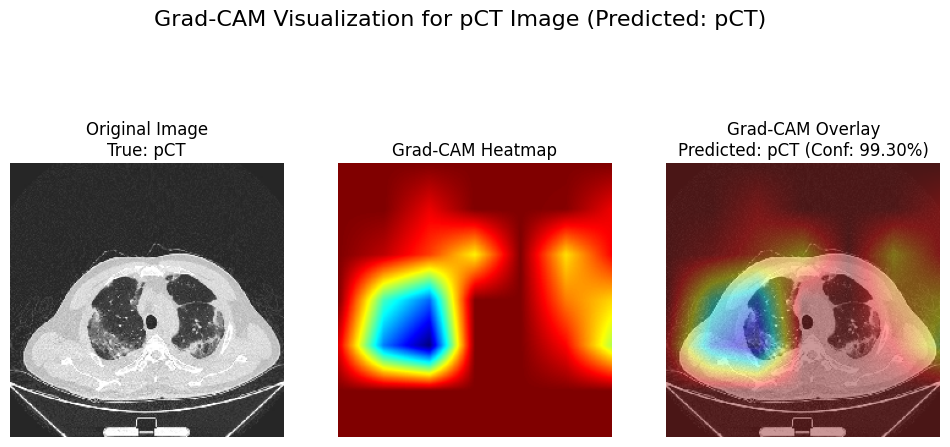


--- Image for pCT (Total 2) ---
Sample Image True Class: pCT
Sample Image Predicted Class: pCT (Confidence: 95.57%)


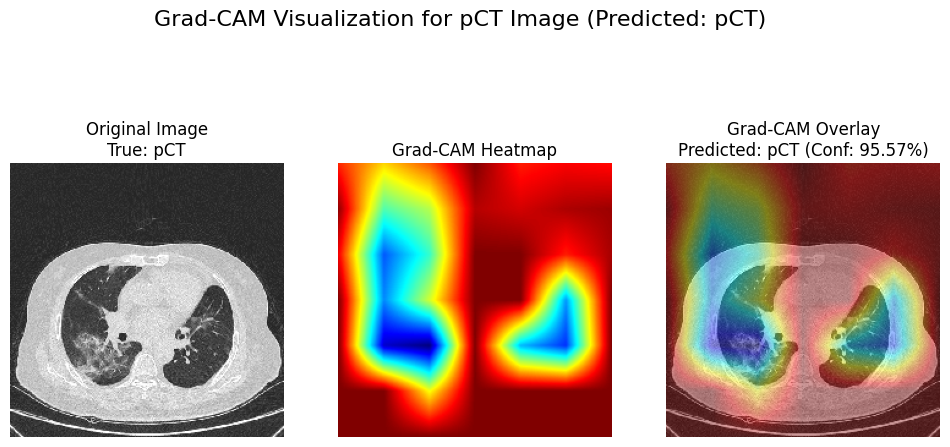


--- Image for pCT (Total 3) ---
Sample Image True Class: pCT
Sample Image Predicted Class: pCT (Confidence: 98.46%)


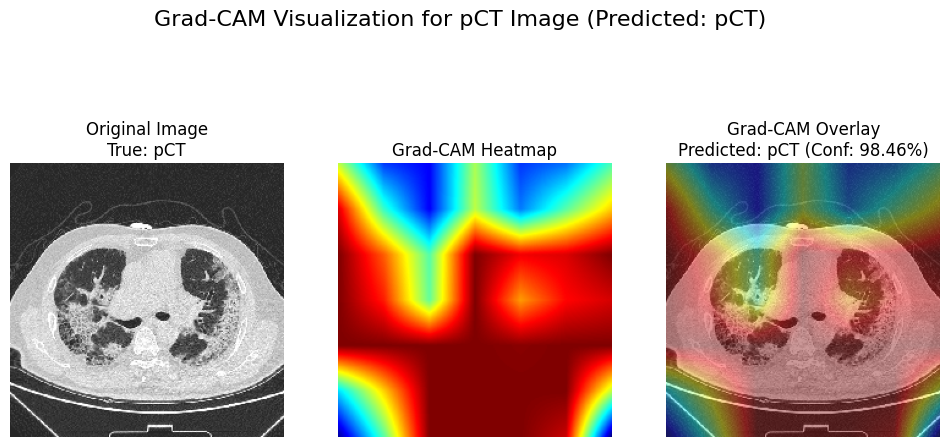


Finished generating Grad-CAM visualizations for 9 images (up to 3 per class). Check '/content/drive/MyDrive/iCTCF_CT_New/ConvNeXtTiny-28-4/gradcam_outputs' for the saved plots.


In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import os
import cv2
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, load_img
from tensorflow.keras.applications.convnext import preprocess_input # Make sure ConvNeXt is imported for preprocess_input
from tensorflow.keras.models import load_model
from tf_keras_vis.gradcam import Gradcam
from tf_keras_vis.utils.model_modifiers import ReplaceToLinear
from tf_keras_vis.utils.scores import CategoricalScore

# ============================
# 📁 Paths (Re-define for robustness)
# ============================
BASE_PATH = '/content/drive/MyDrive/iCTCF_CT_New'
train_dir = f'{BASE_PATH}/train'
val_dir   = f'{BASE_PATH}/validation'
test_dir  = f'{BASE_PATH}/test'

# ============================
# ⚙️ Parameters (Re-define for robustness)
# ============
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 3 # Assuming 3 classes based on previous output

# ============================
# 📦 Data Generators (Re-initialize for robustness)
# ============================
val_test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

test_gen = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

# ============================
# 🧠 Load Fine-tuned Model (Re-load for robustness)
# ============================
DATE = "2026-04-28" # Ensure this matches your saved model's date
finetuned_model_path = f"{BASE_PATH}/final_best_finetuned_ConvNeXtTiny_{DATE}.keras"
model_finetuned = load_model(finetuned_model_path)
print(f"Loaded fine-tuned model from: {finetuned_model_path}")

# --- Configuration for visualizing multiple images ---
images_per_class_target = 3 # Number of images to visualize from each class

# Define the directory to save the Grad-CAM outputs
output_dir = f'{BASE_PATH}/ConvNeXtTiny-28-4/gradcam_outputs'
os.makedirs(output_dir, exist_ok=True)
print(f"Grad-CAM outputs will be saved to: {output_dir}")

# Get class names from the generator
class_names = list(test_gen.class_indices.keys())
num_classes = len(class_names)

functional_model_for_gradcam = model_finetuned

print(f"Generating Grad-CAM for {images_per_class_target} images from each of the {num_classes} classes from the test set...")

visualized_per_class = {class_name: 0 for class_name in class_names}
total_visualized_count = 0

# Reset test_gen to ensure we start from the beginning of the dataset
test_gen.reset()

# Loop through the test generator indefinitely until we have enough images
# Use a counter to prevent infinite loops if a class has fewer than target images
max_batches_to_process = 1000 # Safety break
batches_processed = 0

for batch_x, batch_y in test_gen:
    batches_processed += 1
    if batches_processed > max_batches_to_process:
        print(f"Reached max batches to process ({max_batches_to_process}). Stopping to prevent infinite loop.")
        break

    for i in range(len(batch_x)):
        sample_image = batch_x[i]
        sample_true_label = np.argmax(batch_y[i])
        sample_true_class = class_names[sample_true_label]

        if visualized_per_class[sample_true_class] < images_per_class_target:
            # Get the actual index of the image within the test_generator's full dataset
            # test_gen.batch_index is 1-indexed for the current batch
            # i is the index within the current batch
            actual_image_idx_in_dataset = (test_gen.batch_index - 1) * test_gen.batch_size + i
            original_filepath = test_gen.filepaths[actual_image_idx_in_dataset]

            # Load the original image for display (without any preprocessing)
            original_image_display = load_img(original_filepath, target_size=IMG_SIZE)
            original_image_display = img_to_array(original_image_display)
            original_image_display = np.uint8(original_image_display) # Convert to uint8 for proper display

            # Predict the class of the sample image
            sample_image_for_pred = np.expand_dims(sample_image, axis=0) # Add batch dimension

            predictions = functional_model_for_gradcam.predict(sample_image_for_pred, verbose=0)
            sample_predicted_class_idx = np.argmax(predictions[0])
            sample_predicted_class = class_names[sample_predicted_class_idx]
            confidence = predictions[0][sample_predicted_class_idx] * 100

            print(f"\n--- Image for {sample_true_class} (Total {visualized_per_class[sample_true_class] + 1}) ---")
            print(f"Sample Image True Class: {sample_true_class}")
            print(f"Sample Image Predicted Class: {sample_predicted_class} (Confidence: {confidence:.2f}%)")

            # Create a Gradcam object with the loaded functional model
            gradcam = Gradcam(functional_model_for_gradcam,
                              model_modifier=ReplaceToLinear(),
                              clone=True)

            # Define score for Grad-CAM. We want to visualize for the predicted class.
            score = CategoricalScore([sample_predicted_class_idx])

            # Generate heatmap
            cam = gradcam(score,
                          sample_image_for_pred,
                          seek_penultimate_conv_layer=True) # Let tf_keras_vis automatically find the layer

            # Reshape heatmap to image size and normalize
            heatmap = cam[0]
            heatmap = np.uint8(255 * heatmap / np.max(heatmap))
            heatmap = cv2.resize(heatmap, IMG_SIZE)

            # Apply colormap to heatmap
            heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

            # Superimpose the heatmap on the original image
            superimposed_img = heatmap * 0.4 + original_image_display * 0.6 # Adjust alpha as needed
            superimposed_img = np.uint8(superimposed_img)

            # Display the results
            plt.figure(figsize=(12, 6))

            plt.subplot(1, 3, 1)
            plt.imshow(original_image_display)
            plt.title(f'Original Image\nTrue: {sample_true_class}')
            plt.axis('off')

            plt.subplot(1, 3, 2)
            plt.imshow(heatmap)
            plt.title('Grad-CAM Heatmap')
            plt.axis('off')

            plt.subplot(1, 3, 3)
            plt.imshow(superimposed_img)
            plt.title(f'Grad-CAM Overlay\nPredicted: {sample_predicted_class} (Conf: {confidence:.2f}%)')
            plt.axis('off')

            plt.suptitle(f'Grad-CAM Visualization for {sample_true_class} Image (Predicted: {sample_predicted_class})', fontsize=16)

            # Save the figure to the specified directory
            filename = f"gradcam_{sample_true_class}_{visualized_per_class[sample_true_class]+1}_pred_{sample_predicted_class}.png"
            plt.savefig(os.path.join(output_dir, filename))
            plt.show()

            visualized_per_class[sample_true_class] += 1
            total_visualized_count += 1

    # Check if we have enough images from all classes
    if all(count >= images_per_class_target for count in visualized_per_class.values()):
        break

print(f"\nFinished generating Grad-CAM visualizations for {total_visualized_count} images (up to {images_per_class_target} per class). Check '{output_dir}' for the saved plots.")

### Inspecting Model Layers for Grad-CAM

To resolve the `ValueError` when generating Grad-CAM, we need to identify a valid convolutional layer within the `model_finetuned` that `tf_keras_vis` can use as the `penultimate_layer`. Printing the model summary will help us see all layer names and types.

Please examine the model summary above to identify a `Conv2D` or `DepthwiseConv2D` layer that is deep within the feature extraction part of the network, but *before* the final classification head (GlobalAveragePooling2D, BatchNormalization, Dense layers). Look for a layer name ending in `_conv` or `_depthwise_conv` within one of the later stages (e.g., `stage_3` or `stage_4` if it exists).

Once you've identified a suitable layer name, I can help you update the `penultimate_layer` argument in the Grad-CAM code.